# Day 33 — Data Visualization (Nigerian Retail Sales Analyzer)

This notebook covers eaborn/Matplotlib Theming, Regional GMV Bar Charts, Revenue Histograms with KDE, Category Boxplots, and Scatter Plots

## Validation goals
- Configure professional plotting themes using Seaborn (`sns.set_theme`) and customized Matplotlib parameters (`rcParams`)
- Construct a regional Gross Merchandise Value (GMV) comparison bar chart with custom currency-formatted axes
- Visualize right-skewed transaction revenue distributions using combined histograms and Kernel Density Estimation (KDE)
- Generate category price dispersion boxplots to illustrate Tukey quartile bounds and price spread across product categories
- Create sampled price vs. quantity scatter plots color-coded by category to evaluate bivariate relationships
- Export publication-quality visualization artifacts (`.png` files) for stakeholder presentation

Visualizations bridge raw numbers and executive decision-making. By plotting regional revenue distributions, price-versus-quantity scatter points, category boxplots, and revenue histograms, we can clearly communicate market trends, skewness, and outliers to stakeholders.

### Core Visualization Objectives

1. Regional Revenue Comparison: A bar chart comparing total Gross Merchandise Value (GMV) across commercial market hubs (Lagos, Abuja, Kano, Onitsha).

2. Transaction Dynamics (Scatter Plot): Examining the relationship between item price and units purchased.

3. Distribution & Skewness (Histogram + KDE): Visualizing the heavy right-skew of transaction revenues.

4. Category Pricing Spread (Boxplot): Using Tukey quartile bounds to illustrate price variance and outliers across product categories.


### Implementation Script:

Loaded 5,000 rows for visualization generation.


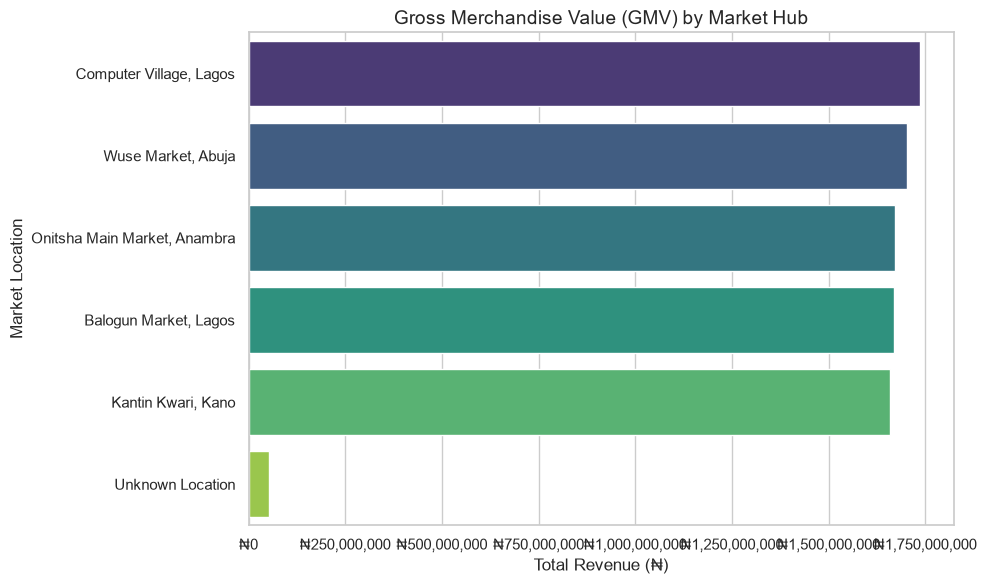

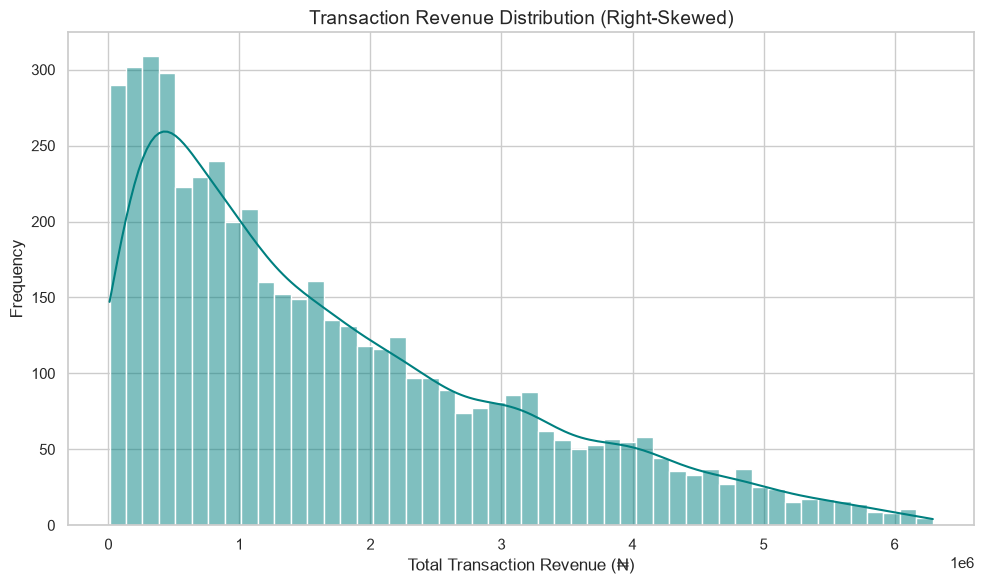

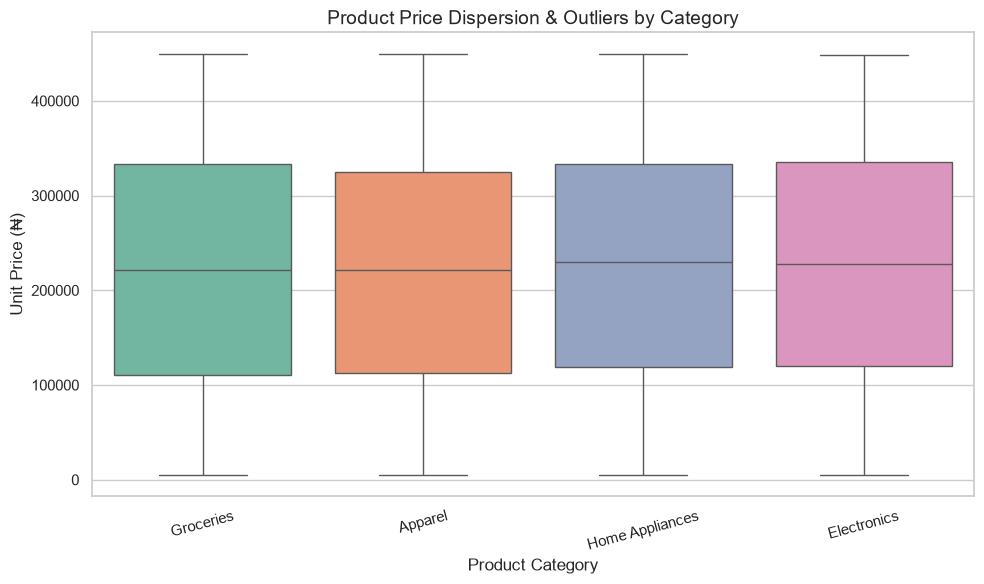

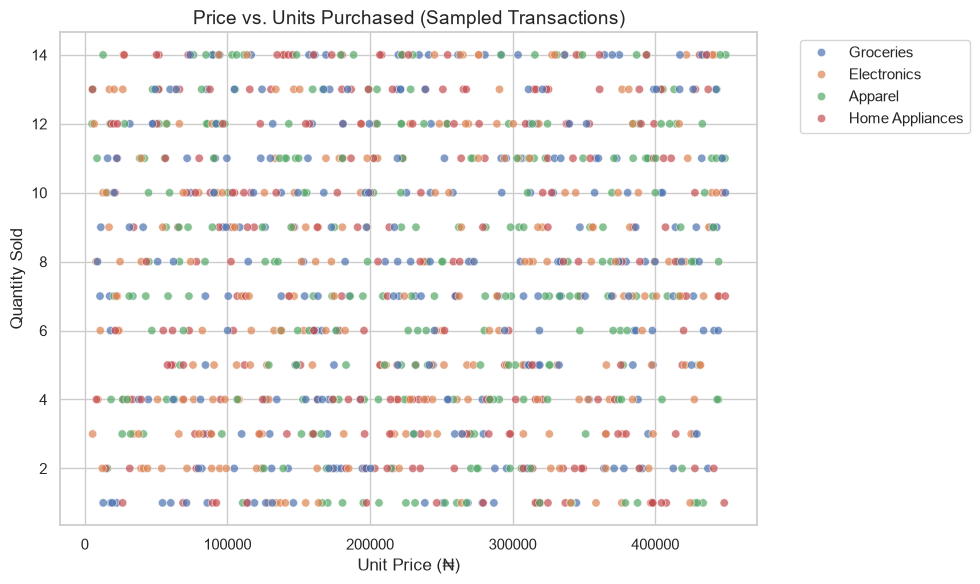

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set professional plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 12
})

# 1. Load Cleaned Dataset
df = pd.read_csv("cleaned_retail_sales.csv", parse_dates=["date"])
df["total_revenue"] = df["price"] * df["quantity"]

print(f"Loaded {len(df):,} rows for visualization generation.")

# ==========================================
# Figure 1: Regional Revenue Comparison (Bar Plot)
# ==========================================
plt.figure()
regional_rev = df.groupby("location", as_index=False)["total_revenue"].sum().sort_values(by="total_revenue", ascending=False)

ax = sns.barplot(
    data=regional_rev, 
    x="total_revenue", 
    y="location", 
    palette="viridis",
    hue="location",
    legend=False
)
plt.title("Gross Merchandise Value (GMV) by Market Hub")
plt.xlabel("Total Revenue (₦)")
plt.ylabel("Market Location")

# Format x-axis with comma separators
ax.xaxis.set_major_formatter('₦{x:,.0f}')
plt.tight_layout()
plt.savefig("regional_revenue_chart.png", dpi=300)
plt.show()


# ==========================================
# Figure 2: Revenue Distribution (Histogram + KDE)
# ==========================================
plt.figure()
sns.histplot(
    data=df, 
    x="total_revenue", 
    kde=True, 
    bins=50, 
    color="teal"
)
plt.title("Transaction Revenue Distribution (Right-Skewed)")
plt.xlabel("Total Transaction Revenue (₦)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("revenue_distribution.png", dpi=300)
plt.show()


# ==========================================
# Figure 3: Category Price Spread (Boxplot)
# ==========================================
plt.figure()
sns.boxplot(
    data=df, 
    x="category", 
    y="price", 
    palette="Set2",
    hue="category",
    legend=False
)
plt.title("Product Price Dispersion & Outliers by Category")
plt.xlabel("Product Category")
plt.ylabel("Unit Price (₦)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("category_price_boxplot.png", dpi=300)
plt.show()


# ==========================================
# Figure 4: Price vs. Quantity Scatter Plot
# ==========================================
plt.figure()
sns.scatterplot(
    data=df.sample(1000, random_state=42), # Sample for clean rendering
    x="price", 
    y="quantity", 
    hue="category", 
    alpha=0.7, 
    palette="deep"
)
plt.title("Price vs. Units Purchased (Sampled Transactions)")
plt.xlabel("Unit Price (₦)")
plt.ylabel("Quantity Sold")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig("price_vs_quantity_scatter.png", dpi=300)
plt.show()